## Week 4 — Statistical Analysis and Hypothesis Testing Using Python

### 1. Install and import the required libraries

In [1]:
# Install required libraries if needed
# Uncomment this line if you get an import error
# !pip install pandas numpy scipy statsmodels openpyxl matplotlib seaborn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from statsmodels.stats.weightstats import DescrStatsW, CompareMeans
from statsmodels.stats.proportion import proportions_ztest, proportion_confint
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.contingency_tables import Table2x2
import statsmodels.api as sm
import statsmodels.formula.api as smf

print("All libraries imported successfully!")

All libraries imported successfully!


### 2. Load and inspect the dataset

In [4]:
df = pd.read_excel("Raw Data Supermaket Sales.xlsx")
df

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Month,Day,Year,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1,5,2019,2019-01-05,13:08:00,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3,8,2019,2019-03-08,10:29:00,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,16.2155,340.5255,3,3,2019,2019-03-03,13:23:00,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,23.2880,489.0480,1,27,2019,2019-01-27,20:33:00,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,30.2085,634.3785,2,8,2019,2019-02-08,10:37:00,Ewallet,604.17,4.761905,30.2085,5.3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,233-67-5758,C,Naypyitaw,Normal,Male,Health and beauty,40.35,1,2.0175,42.3675,1,29,2019,2019-01-29,13:46:00,Ewallet,40.35,4.761905,2.0175,6.2
996,303-96-2227,B,Mandalay,Normal,Female,Home and lifestyle,97.38,10,48.6900,1022.4900,3,2,2019,2019-03-02,17:16:00,Ewallet,973.80,4.761905,48.6900,4.4
997,727-02-1313,A,Yangon,Member,Male,Food and beverages,31.84,1,1.5920,33.4320,2,9,2019,2019-02-09,13:22:00,Cash,31.84,4.761905,1.5920,7.7
998,347-56-2442,A,Yangon,Normal,Male,Home and lifestyle,65.82,1,3.2910,69.1110,2,22,2019,2019-02-22,15:33:00,Cash,65.82,4.761905,3.2910,4.1


In [5]:
print(df.head())

    Invoice ID Branch       City Customer type  Gender  \
0  750-67-8428      A     Yangon        Member  Female   
1  226-31-3081      C  Naypyitaw        Normal  Female   
2  631-41-3108      A     Yangon        Normal    Male   
3  123-19-1176      A     Yangon        Member    Male   
4  373-73-7910      A     Yangon        Normal    Male   

             Product line  Unit price  Quantity   Tax 5%     Total  Month  \
0       Health and beauty       74.69         7  26.1415  548.9715      1   
1  Electronic accessories       15.28         5   3.8200   80.2200      3   
2      Home and lifestyle       46.33         7  16.2155  340.5255      3   
3       Health and beauty       58.22         8  23.2880  489.0480      1   
4       Sports and travel       86.31         7  30.2085  634.3785      2   

   Day  Year       Date      Time      Payment    cogs  \
0    5  2019 2019-01-05  13:08:00      Ewallet  522.83   
1    8  2019 2019-03-08  10:29:00         Cash   76.40   
2    3  2019 2

In [6]:
print("\nDataset shape:", df.shape)


Dataset shape: (1000, 20)


In [7]:
print("\nColumns:")
print(df.columns.tolist())


Columns:
['Invoice ID', 'Branch', 'City', 'Customer type', 'Gender', 'Product line', 'Unit price', 'Quantity', 'Tax 5%', 'Total', 'Month', 'Day', 'Year', 'Date', 'Time', 'Payment', 'cogs', 'gross margin percentage', 'gross income', 'Rating']


In [8]:
print("\nDataset information:")
df.info()


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   Invoice ID               1000 non-null   object        
 1   Branch                   1000 non-null   object        
 2   City                     1000 non-null   object        
 3   Customer type            1000 non-null   object        
 4   Gender                   1000 non-null   object        
 5   Product line             1000 non-null   object        
 6   Unit price               1000 non-null   float64       
 7   Quantity                 1000 non-null   int64         
 8   Tax 5%                   1000 non-null   float64       
 9   Total                    1000 non-null   float64       
 10  Month                    1000 non-null   int64         
 11  Day                      1000 non-null   int64         
 12  Year         

In [9]:
print("\nMissing values:")
print(df.isnull().sum())


Missing values:
Invoice ID                 0
Branch                     0
City                       0
Customer type              0
Gender                     0
Product line               0
Unit price                 0
Quantity                   0
Tax 5%                     0
Total                      0
Month                      0
Day                        0
Year                       0
Date                       0
Time                       0
Payment                    0
cogs                       0
gross margin percentage    0
gross income               0
Rating                     0
dtype: int64


In [10]:
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

In [12]:
numeric_columns = [
    "Unit price",
    "Quantity",
    "Total",
    "Tax 5%",
    "cogs",
    "gross income",
    "Rating"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

In [13]:
required_columns = [
    "Branch", "Gender", "Customer type",
    "Product line", "Payment", "Total",
    "Quantity", "Rating", "gross income"
]

df = df.dropna(subset=required_columns).copy()

In [14]:
print("Dataset prepared successfully.")
print("Rows available for analysis:", len(df))

Dataset prepared successfully.
Rows available for analysis: 1000


### 3. Set up a helper function for hypothesis testing

In [16]:
ALPHA = 0.05

def interpret_p_value(p_value):
    if p_value < ALPHA:
        return "Statistically significant: Reject the null hypothesis."
    else:
        return "Not statistically significant: Fail to reject the null hypothesis."

### 4. Hypothesis Test 1: Is average spending different between Member and Normal customers?

In [17]:
member_sales = df.loc[
    df["Customer type"].str.strip().str.lower() == "member",
    "Total"
]

normal_sales = df.loc[
    df["Customer type"].str.strip().str.lower() == "normal",
    "Total"
]

In [19]:
print("Member customers")
print("Sample size:", len(member_sales))
print("Mean transaction value:", member_sales.mean())
print("Standard deviation:", member_sales.std())


Member customers
Sample size: 501
Mean transaction value: 327.7913053892216
Standard deviation: 247.99378178667004


In [20]:
print("\nNormal customers")
print("Sample size:", len(normal_sales))
print("Mean transaction value:", normal_sales.mean())
print("Standard deviation:", normal_sales.std())


Normal customers
Sample size: 499
Mean transaction value: 318.12285571142286
Standard deviation: 243.9028004475982


In [21]:
t_stat, p_value = stats.ttest_ind(
    member_sales,
    normal_sales,
    equal_var=False
)

print("\nWelch's t-test")
print("T-statistic:", t_stat)
print("P-value:", p_value)
print(interpret_p_value(p_value))


Welch's t-test
T-statistic: 0.6215475684596813
P-value: 0.5343813752186699
Not statistically significant: Fail to reject the null hypothesis.


In [22]:
# Difference in mean transaction value
mean_difference = member_sales.mean() - normal_sales.mean()

# Welch-Satterthwaite degrees of freedom
n1 = len(member_sales)
n2 = len(normal_sales)

v1 = member_sales.var(ddof=1)
v2 = normal_sales.var(ddof=1)

se_difference = np.sqrt(v1/n1 + v2/n2)

df_welch = (v1/n1 + v2/n2)**2 / (
    (v1/n1)**2/(n1-1) +
    (v2/n2)**2/(n2-1)
)

critical_value = stats.t.ppf(0.975, df_welch)

ci_lower = mean_difference - critical_value * se_difference
ci_upper = mean_difference + critical_value * se_difference

# Cohen's d using pooled standard deviation
pooled_sd = np.sqrt(
    ((n1-1)*v1 + (n2-1)*v2) / (n1+n2-2)
)

cohens_d = mean_difference / pooled_sd

print("Mean difference (Member - Normal):", mean_difference)
print("95% confidence interval:", (ci_lower, ci_upper))
print("Cohen's d effect size:", cohens_d)

Mean difference (Member - Normal): 9.66844967779872
95% confidence interval: (np.float64(-20.85669009360763), np.float64(40.193589449205064))
Cohen's d effect size: 0.03930888949942511


### 5. Hypothesis Test 2: Is there a relationship between quantity purchased and transaction value?

Pearson correlation coefficient: 0.7055101859433062
P-value: 2.063947519679584e-151
Statistically significant: Reject the null hypothesis.


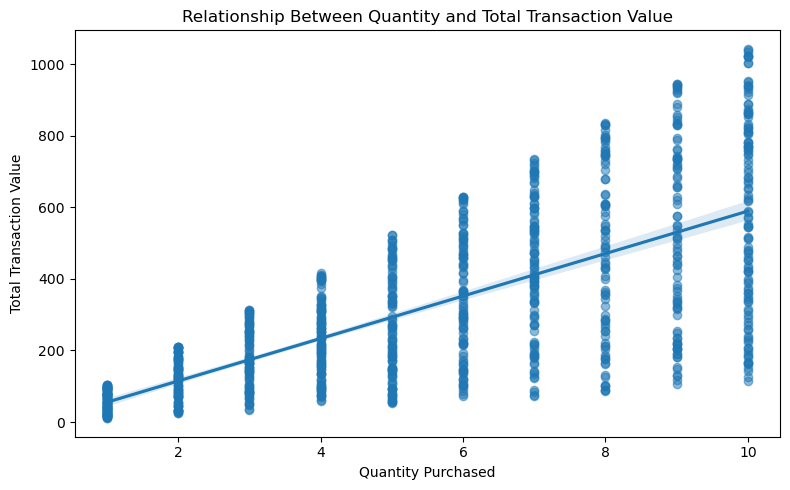

In [23]:
# Pearson correlation
correlation, p_value = stats.pearsonr(
    df["Quantity"],
    df["Total"]
)

print("Pearson correlation coefficient:", correlation)
print("P-value:", p_value)
print(interpret_p_value(p_value))

# Scatter plot
plt.figure(figsize=(8, 5))

sns.regplot(
    data=df,
    x="Quantity",
    y="Total",
    scatter_kws={"alpha": 0.5}
)

plt.title("Relationship Between Quantity and Total Transaction Value")
plt.xlabel("Quantity Purchased")
plt.ylabel("Total Transaction Value")
plt.tight_layout()
plt.show()

### 6. Hypothesis Test 3: Is customer gender associated with product line?

In [24]:
# Create a contingency table
contingency_table = pd.crosstab(
    df["Gender"],
    df["Product line"]
)

print("Contingency Table:")
print(contingency_table)

# Perform Chi-square test
chi2, p_value, degrees_freedom, expected = stats.chi2_contingency(
    contingency_table
)

print("\nChi-square statistic:", chi2)
print("Degrees of freedom:", degrees_freedom)
print("P-value:", p_value)

print("\nExpected frequencies:")
print(pd.DataFrame(
    expected,
    index=contingency_table.index,
    columns=contingency_table.columns
))

print("\n", interpret_p_value(p_value))

Contingency Table:
Product line  Electronic accessories  Fashion accessories  Food and beverages  \
Gender                                                                          
Female                            84                   96                  90   
Male                              86                   82                  84   

Product line  Health and beauty  Home and lifestyle  Sports and travel  
Gender                                                                  
Female                       64                  79                 88  
Male                         88                  81                 78  

Chi-square statistic: 5.7444558595826445
Degrees of freedom: 5
P-value: 0.33188385805539106

Expected frequencies:
Product line  Electronic accessories  Fashion accessories  Food and beverages  \
Gender                                                                          
Female                         85.17               89.178              87.174   
Male 

In [25]:
n = contingency_table.to_numpy().sum()

rows, cols = contingency_table.shape

cramers_v = np.sqrt(
    chi2 / (n * min(rows - 1, cols - 1))
)

print("Cramér's V:", cramers_v)

# Check expected frequencies
print(
    "Minimum expected frequency:",
    expected.min()
)

print(
    "All expected frequencies >= 5:",
    (expected >= 5).all()
)

Cramér's V: 0.07579218864489035
Minimum expected frequency: 75.848
All expected frequencies >= 5: True


### 7. Hypothesis Test 4: Are average customer ratings different across product lines?

In [26]:
# Group ratings by product line
rating_groups = [
    group["Rating"].values
    for _, group in df.groupby("Product line")
]

# One-way ANOVA
f_stat, p_value = stats.f_oneway(*rating_groups)

print("ANOVA F-statistic:", f_stat)
print("P-value:", p_value)
print(interpret_p_value(p_value))

ANOVA F-statistic: 0.5398947419806559
P-value: 0.7461368538761987
Not statistically significant: Fail to reject the null hypothesis.


In [27]:
rating_summary = df.groupby("Product line")["Rating"].agg(
    ["count", "mean", "std", "var"]
)

print(rating_summary)

# Levene's test for equality of variances
levene_stat, levene_p = stats.levene(*rating_groups)

print("\nLevene's test statistic:", levene_stat)
print("Levene's test p-value:", levene_p)

                        count      mean       std       var
Product line                                               
Electronic accessories    170  6.924706  1.702028  2.896901
Fashion accessories       178  7.029213  1.713437  2.935865
Food and beverages        174  7.113218  1.715181  2.941847
Health and beauty         152  7.003289  1.763817  3.111049
Home and lifestyle        160  6.837500  1.718627  2.953679
Sports and travel         166  6.916265  1.714477  2.939431

Levene's test statistic: 0.32205264606370887
Levene's test p-value: 0.8998689480966134


In [28]:
if p_value < ALPHA:
    tukey_results = pairwise_tukeyhsd(
        endog=df["Rating"],
        groups=df["Product line"],
        alpha=ALPHA
    )

    print(tukey_results)
else:
    print(
        "ANOVA is not statistically significant. "
        "No follow-up Tukey test is conducted."
    )

ANOVA is not statistically significant. No follow-up Tukey test is conducted.


### 8. Hypothesis Test 5: Is average transaction value different between branches?

In [29]:
# Display average transaction value by branch
branch_summary = df.groupby("Branch")["Total"].agg(
    ["count", "mean", "std"]
)

print(branch_summary)

# Create groups
branch_groups = [
    group["Total"].values
    for _, group in df.groupby("Branch")
]

# One-way ANOVA
f_stat, p_value = stats.f_oneway(*branch_groups)

print("\nBranch ANOVA")
print("F-statistic:", f_stat)
print("P-value:", p_value)
print(interpret_p_value(p_value))

        count        mean         std
Branch                               
A         340  312.354031  231.640025
B         332  319.872506  242.447565
C         328  337.099715  263.160870

Branch ANOVA
F-statistic: 0.8845828327760512
P-value: 0.413210174367147
Not statistically significant: Fail to reject the null hypothesis.


In [30]:
if p_value < ALPHA:
    branch_tukey = pairwise_tukeyhsd(
        endog=df["Total"],
        groups=df["Branch"],
        alpha=ALPHA
    )

    print(branch_tukey)
else:
    print(
        "There is insufficient evidence of a difference "
        "in mean transaction value among branches."
    )

There is insufficient evidence of a difference in mean transaction value among branches.


### 9. Hypothesis Test 6: Is monthly sales variation statistically significant?

In [31]:
# Extract month from Date
df["Month_Name"] = df["Date"].dt.strftime("%B")

month_order = ["January", "February", "March"]

monthly_groups = [
    df.loc[df["Month_Name"] == month, "Total"].dropna().values
    for month in month_order
]

# Display monthly summary
monthly_summary = df.groupby("Month_Name")["Total"].agg(
    ["count", "mean", "median", "std", "sum"]
)

print(monthly_summary.reindex(month_order))

# One-way ANOVA
f_stat, p_value = stats.f_oneway(*monthly_groups)

print("\nMonthly ANOVA")
print("F-statistic:", f_stat)
print("P-value:", p_value)
print(interpret_p_value(p_value))

            count        mean     median         std         sum
Month_Name                                                      
January       352  330.374625  270.13875  247.378739  116291.868
February      303  320.856020  252.75600  244.484553   97219.374
March         345  317.262339  237.42600  246.109322  109455.507

Monthly ANOVA
F-statistic: 0.26336478725985
P-value: 0.7685149658919843
Not statistically significant: Fail to reject the null hypothesis.


### 10. Hypothesis Test 7: Can unit price predict gross income?

In [32]:
# Prepare variables
regression_data = df[["Unit price", "gross income"]].dropna()

X = regression_data[["Unit price"]]
y = regression_data["gross income"]

# Add intercept
X = sm.add_constant(X)

# Fit regression model
model = sm.OLS(y, X).fit()

# Display complete statistical output
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:           gross income   R-squared:                       0.402
Model:                            OLS   Adj. R-squared:                  0.401
Method:                 Least Squares   F-statistic:                     670.6
Date:                Mon, 19 Oct 2026   Prob (F-statistic):          1.61e-113
Time:                        21:34:56   Log-Likelihood:                -3621.8
No. Observations:                1000   AIC:                             7248.
Df Residuals:                     998   BIC:                             7257.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.2182      0.667     -0.327      0.7

In [33]:
print("Regression coefficient:")
print(model.params)

print("\n95% confidence intervals:")
print(model.conf_int())

print("\nP-values:")
print(model.pvalues)

print("\nR-squared:", model.rsquared)

Regression coefficient:
const        -0.218190
Unit price    0.280168
dtype: float64

95% confidence intervals:
                   0         1
const      -1.527005  1.090625
Unit price  0.258938  0.301398

P-values:
const          7.436322e-01
Unit price    1.609952e-113
dtype: float64

R-squared: 0.40190792976821454


### 11. Check the regression assumptions

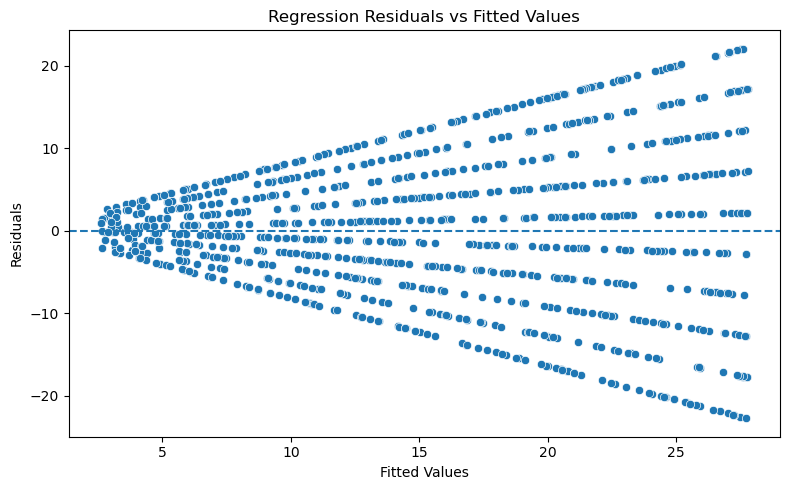

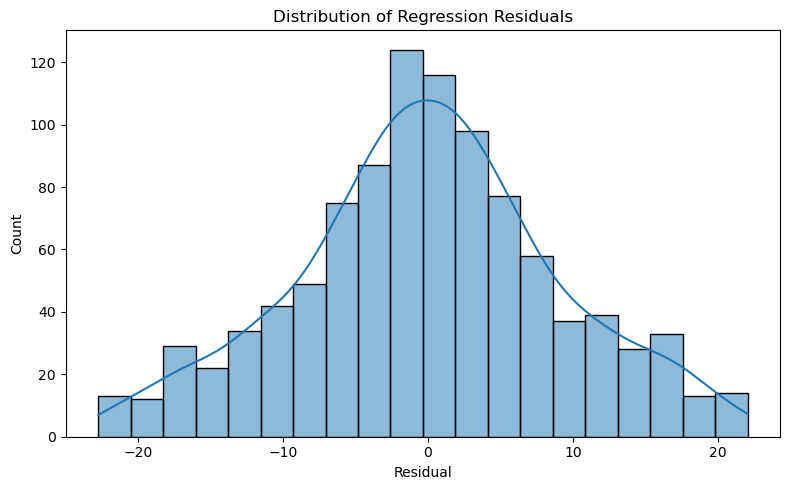

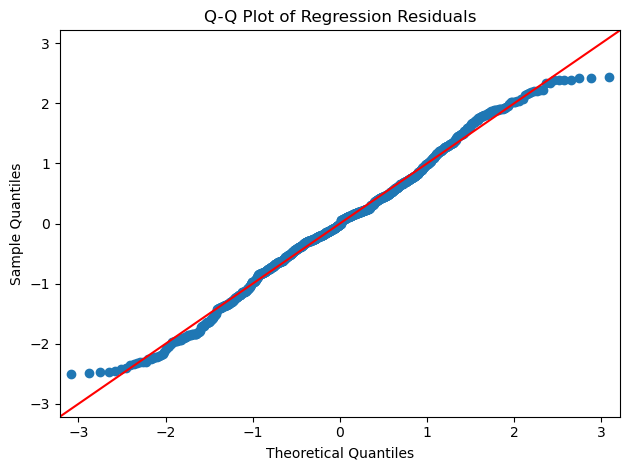

In [34]:
# Calculate fitted values and residuals
fitted_values = model.fittedvalues
residuals = model.resid

# Residuals versus fitted values
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=fitted_values,
    y=residuals
)

plt.axhline(0, linestyle="--")
plt.title("Regression Residuals vs Fitted Values")
plt.xlabel("Fitted Values")
plt.ylabel("Residuals")
plt.tight_layout()
plt.show()

# Residual distribution
plt.figure(figsize=(8, 5))

sns.histplot(
    residuals,
    kde=True
)

plt.title("Distribution of Regression Residuals")
plt.xlabel("Residual")
plt.tight_layout()
plt.show()

# Q-Q plot
sm.qqplot(residuals, line="45", fit=True)
plt.title("Q-Q Plot of Regression Residuals")
plt.tight_layout()
plt.show()

### 12. Create a final summary table of statistical tests

In [35]:
results = []

# Test 1: Member vs Normal customers
results.append({
    "Test": "Welch's t-test",
    "Research Question": "Do Member and Normal customers have different mean transaction values?",
    "Statistic": t_stat,
    "P-value": p_value
})

# Note:
# The variables t_stat and p_value are reused in the notebook.
# For a final report, store each test's statistic and p-value
# immediately after running that test to avoid overwriting results.

In [36]:
# Example structure for recording results safely
statistical_results = []

def record_result(test_name, research_question, statistic, p_value):
    statistical_results.append({
        "Test": test_name,
        "Research Question": research_question,
        "Test Statistic": statistic,
        "P-value": p_value,
        "Decision": (
            "Reject H0"
            if p_value < ALPHA
            else "Fail to reject H0"
        )
    })

# Example:
# record_result(
#     "Welch's t-test",
#     "Difference in mean transaction value by customer type",
#     t_stat,
#     p_value
# )

# After recording each test:
# results_df = pd.DataFrame(statistical_results)
# print(results_df)
# results_df.to_csv("Week4_Hypothesis_Test_Results.csv", index=False)

In [ ]:
### 13. Save your statistical results